<a href="https://colab.research.google.com/github/VINO234/VINO234/blob/main/pauvrete_afrique_ouest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pauvreté extrême en Afrique de l'Ouest : quels indicateurs y sont associés ?

**Auteur :** Kévin Alaye · **Source des données :** Banque mondiale (World Development Indicators)

**Question :** parmi quelques indicateurs socio-économiques courants, lesquels sont associés au taux de pauvreté extrême dans les pays d'Afrique de l'Ouest, et peut-on construire un modèle simple pour l'estimer ?

## Étape 1 : installation et imports

In [ ]:
!pip install -q wbgapi

import wbgapi as wb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Étape 2 : récupération des données

Les codes d'indicateurs viennent de data.worldbank.org. Le code `SI.POV.DDAY` correspond au taux de pauvreté extrême ; le seuil exact (en dollars par jour) a été révisé par la Banque mondiale, donc vérifie-le sur le site et note-le dans ton README.

In [ ]:
pays = ["BEN", "TGO", "NGA", "GHA", "NER", "BFA", "MLI", "CIV", "SEN", "GIN", "SLE", "LBR", "GMB", "GNB"]

indicateurs = {
    "SI.POV.DDAY": "pauvrete",
    "NY.GDP.PCAP.CD": "pib_hab",
    "EG.ELC.ACCS.ZS": "electricite",
    "IT.NET.USER.ZS": "internet",
    "SP.DYN.LE00.IN": "esperance_vie",
    "SE.SEC.ENRR": "scolarisation_sec",
}

raw = wb.data.DataFrame(
    list(indicateurs.keys()), pays,
    time=range(2000, 2024), columns="series", numericTimeKeys=True
)
raw = raw.rename(columns=indicateurs).reset_index()
raw.columns.name = None
raw = raw.rename(columns={"economy": "pays", "time": "annee"})
raw["annee"] = raw["annee"].astype(str).str.replace("YR", "").astype(int)

print(raw.shape)
raw.head()

(336, 8)


,pays,annee,electricite,internet,pib_hab,scolarisation_sec,pauvrete,esperance_vie
0,BEN,2000,21.5,0.225248,487.424141,20.000540,NaN,56.594
1,BEN,2001,21.9,0.363418,492.401500,21.710440,NaN,56.654
2,BEN,2002,23.4,0.702946,546.463830,23.584669,NaN,56.851
3,BEN,2003,24.3,0.951327,676.002878,24.900120,70.5,57.092
4,BEN,2004,25.2,1.182541,758.695804,26.704149,NaN,57.346


## Étape 3 : inspection et nettoyage

Les données de pauvreté viennent d'enquêtes auprès des ménages, réalisées tous les quelques années : il y a donc beaucoup de valeurs manquantes. Choix retenu : pour les autres indicateurs, on interpole dans le temps pays par pays ; on ne garde ensuite que les années où le taux de pauvreté est réellement observé.

In [ ]:
raw.info()
print(raw.isna().sum())
print("Observations de pauvreté par pays :")
print(raw.groupby("pays")["pauvrete"].count())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pays               336 non-null    object 
 1   annee              336 non-null    int64  
 2   electricite        327 non-null    float64
 3   internet           336 non-null    float64
 4   pib_hab            336 non-null    float64
 5   scolarisation_sec  188 non-null    float64
 6   pauvrete           63 non-null     float64
 7   esperance_vie      336 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 21.1+ KB
pays                   0
annee                  0
electricite            9
internet               0
pib_hab                0
scolarisation_sec    148
pauvrete             273
esperance_vie          0
dtype: int64
Observations de pauvreté par pays :
pays
BEN    5
BFA    5
CIV    5
GHA    3
GIN    4
GMB    4
GNB    4
LBR    3
MLI    5
NER    6
NGA    6


In [ ]:
df = raw.sort_values(["pays", "annee"]).copy()
predicteurs = ["pib_hab", "electricite", "internet", "esperance_vie", "scolarisation_sec"]

# interpolation pays par pays (les bords prennent la valeur la plus proche)
df[predicteurs] = df.groupby("pays")[predicteurs].transform(
    lambda s: s.interpolate(limit_direction="both")
)

# on garde uniquement les années où la pauvreté est observée
data = df.dropna(subset=["pauvrete"] + predicteurs).copy()
data["log_pib_hab"] = np.log(data["pib_hab"])

print(data.shape, "observations,", data["pays"].nunique(), "pays")
data.head()

(63, 9) observations, 14 pays


,pays,annee,electricite,internet,pib_hab,scolarisation_sec,pauvrete,esperance_vie,log_pib_hab
3,BEN,2003,24.3,0.951327,676.002878,24.900120,70.5,57.092,6.516197
11,BEN,2011,36.9,4.148323,1059.413589,45.729469,68.4,58.462,6.965471
15,BEN,2015,29.6,11.255000,1002.418869,55.133308,65.8,59.123,6.910171
18,BEN,2018,39.0,19.000000,1151.740970,49.640230,37.2,59.710,7.049030
21,BEN,2021,42.0,28.204700,1318.651581,44.273800,27.2,59.610,7.184365


## Étape 4 : exploration et visualisation

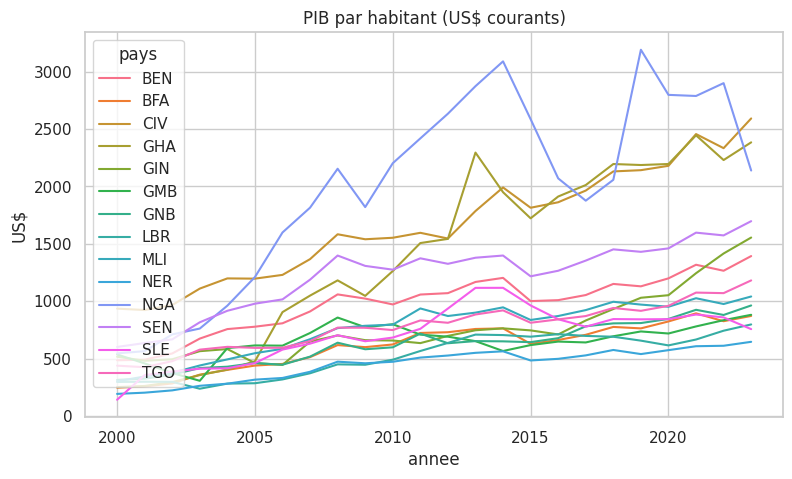

In [ ]:
# 1. PIB par habitant
plt.figure(figsize=(9, 5))
sns.lineplot(data=df, x="annee", y="pib_hab", hue="pays")
plt.title("PIB par habitant (US$ courants)")
plt.ylabel("US$")
plt.show()

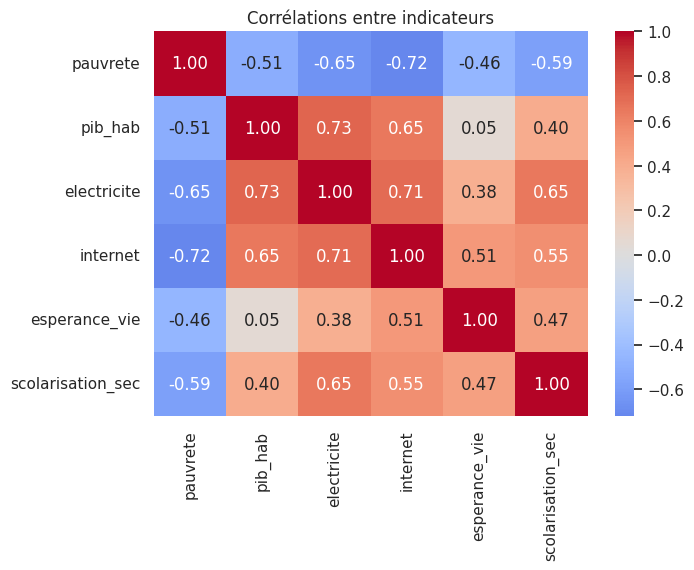

In [ ]:
# 2. Corrélations
plt.figure(figsize=(7, 5))
sns.heatmap(data[["pauvrete"] + predicteurs].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre indicateurs")
plt.show()

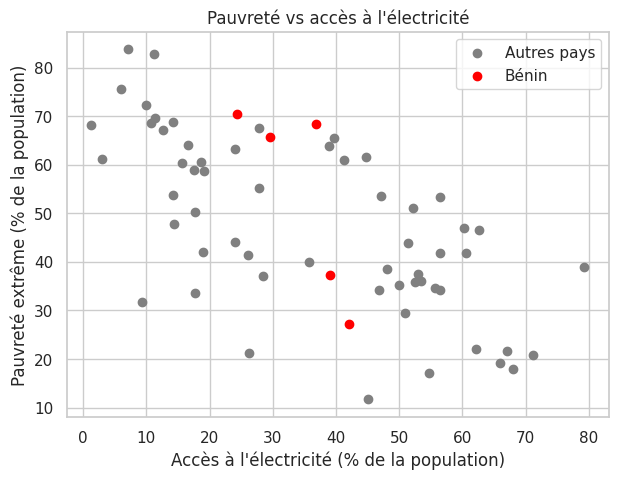

In [ ]:
# 3. Pauvreté vs accès à l'électricité (Bénin en rouge)
plt.figure(figsize=(7, 5))
est_benin = data["pays"] == "BEN"
plt.scatter(data.loc[~est_benin, "electricite"], data.loc[~est_benin, "pauvrete"], color="grey", label="Autres pays")
plt.scatter(data.loc[est_benin, "electricite"], data.loc[est_benin, "pauvrete"], color="red", label="Bénin")
plt.xlabel("Accès à l'électricité (% de la population)")
plt.ylabel("Pauvreté extrême (% de la population)")
plt.legend()
plt.title("Pauvreté vs accès à l'électricité")
plt.show()

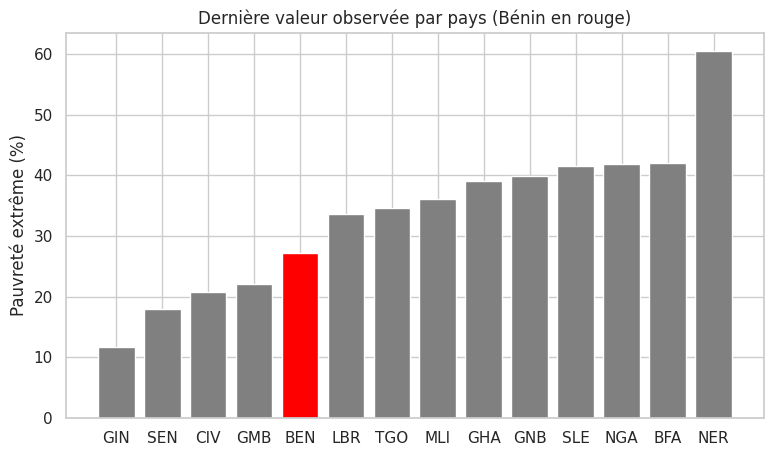

In [ ]:
# 4. Classement : dernière valeur de pauvreté observée par pays
dernier = data.sort_values("annee").groupby("pays").tail(1).sort_values("pauvrete")
couleurs = ["red" if p == "BEN" else "grey" for p in dernier["pays"]]

plt.figure(figsize=(9, 5))
plt.bar(dernier["pays"], dernier["pauvrete"], color=couleurs)
plt.ylabel("Pauvreté extrême (%)")
plt.title("Dernière valeur observée par pays (Bénin en rouge)")
plt.show()

## Étape 5 : modèle simple (régression linéaire)

Attention : plusieurs lignes viennent du même pays, donc un découpage aléatoire entraînement/test donne un score trop optimiste. On ajoute une validation croisée **par pays** (chaque pays est testé alors qu'il n'a pas servi à entraîner le modèle), qui est plus honnête.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X = data[["log_pib_hab", "electricite", "scolarisation_sec"]]
y = data["pauvrete"]

# Découpage aléatoire
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
modele = LinearRegression().fit(X_train, y_train)
pred = modele.predict(X_test)
print("R² (test aléatoire) :", round(r2_score(y_test, pred), 3))
print("Erreur absolue moyenne (points de %) :", round(mean_absolute_error(y_test, pred), 2))

# Validation croisée par pays
k = min(5, data["pays"].nunique())
scores = cross_val_score(LinearRegression(), X, y, cv=GroupKFold(n_splits=k), groups=data["pays"], scoring="r2")
print("R² (validation par pays) :", scores.round(3), "-> moyenne", round(scores.mean(), 3))

# Coefficients
print(pd.Series(modele.coef_, index=X.columns).round(3))

R² (test aléatoire) : 0.646
Erreur absolue moyenne (points de %) : 8.06
R² (validation par pays) : [ 0.343  0.629  0.261 -0.249  0.257] -> moyenne 0.248
log_pib_hab         -7.824
electricite         -0.235
scolarisation_sec   -0.343
dtype: float64


## Étape 6 : conclusions et limites (à compléter avec tes propres résultats)

- **Principaux constats :** …
- **Performance du modèle :** …
- **Limites :** peu d'observations de pauvreté, valeurs interpolées, corrélation n'est pas causalité, indicateurs nationaux qui masquent les différences régionales.
- **Pistes :** données d'enquêtes ménages (EHCVM), données satellites, modèles non linéaires.